# Image based binding affinity fitting simulations

In which I use the Gillespie simulation for protein complex number fluctuations to produce simulated images and analyze them down to fitting binding affinities with heterospecies partition analysis and my fokker-planck model.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt 
import os
import tifffile as tif
import simulation_classes as sc 
import calculateCumulants as cc
import FitCumulants_corrected as fc
import bayes_fit as bf
# %matplotlib widget

Generator = np.random.default_rng()    

In [17]:
#inverse cumulative density function for exponential waiting time distribution.
def waiting_time(Kon, Koff, Nr, Ng, Nrg):
    return -np.log(Generator.random()) / (Kon*Nr*Ng + Koff*Nrg) 


def choose_transition(Kon, Koff, Nr, Ng, Nrg):
    r = Generator.random()
    if r <  ( (Kon*Nr*Ng) / (Kon*Nr*Ng + Koff*Nrg) ):
        return 1
    else:
        return -1

def run_gillespie(N_r, N_g, N_rg, Tmax, K_on, K_off):
    Nrvals = []
    Ngvals = []
    Nrgvals = []
    Tvals = []

    nr = N_r
    ng = N_g
    nrg = N_rg
    t = 0
    while t < Tmax:
        Tvals.append(t)
        Nrvals.append(nr)
        Ngvals.append(ng)
        Nrgvals.append(nrg)
            
        t += waiting_time(K_on, K_off, nr, ng, nrg)
        dn = choose_transition(K_on, K_off, nr, ng, nrg)
        nrg += dn 
        nr -= dn 
        ng -= dn
    return np.array(Nrvals), np.array(Ngvals), np.array(Nrgvals), np.array(Tvals)

def run_gillespie(N_r, N_g, N_rg, Tmax, K_on, K_off):
    Nrvals = []
    Ngvals = []
    Nrgvals = []
    Tvals = []

    nr = N_r
    ng = N_g
    nrg = N_rg
    t = 0
    while t < Tmax:
        Tvals.append(t)
        Nrvals.append(nr)
        Ngvals.append(ng)
        Nrgvals.append(nrg)
            
        t += waiting_time(K_on, K_off, nr, ng, nrg)
        dn = choose_transition(K_on, K_off, nr, ng, nrg)
        nrg += dn 
        nr -= dn 
        ng -= dn
    return np.array(Nrvals), np.array(Ngvals), np.array(Nrgvals), np.array(Tvals)

def make_time_series(Nr, Ng, Nrg, Tvals, dt, L=None):
    # take gillespie simulation run and translate into discrete time series data.
    if L is None:
        L = int(Tvals[-1]//dt)
    nr = np.zeros(L)
    ng = np.zeros(L)
    nrg = np.zeros(L)
    time = np.zeros(L)

    for i in range(L):
        t = dt*i
        idx = np.argwhere(Tvals <= t)[-1][0]
        time[i] = t
        nr[i] = Nr[idx]
        ng[i] = Ng[idx]
        nrg[i] = Nrg[idx]
    return nr, ng, nrg, time

# Deterministic solution...

#deterministic ODE solving functions
def deterministic_update(nr, ng, nrg, kon, koff):
    drg = kon*nr*ng - koff*nrg
    return drg
    
#forward euler integrator
def solve_deterministic(Nr_i, Ng_i, Nrg_i, Tmax, dt, kon, koff):
    Tvals = np.arange(0, Tmax, dt)
    Nrvals = np.zeros(len(Tvals))
    Ngvals = np.zeros(len(Tvals))
    Nrgvals = np.zeros(len(Tvals))
    Nrvals[0] = Nr_i
    Ngvals[0] = Ng_i
    Nrgvals[0] = Nrg_i
    for i in range(1, len(Tvals)):
        drg = deterministic_update(Nrvals[i-1], Ngvals[i-1], Nrgvals[i-1],kon, koff) * dt 
        Nrgvals[i] = Nrgvals[i-1] + drg
        Nrvals[i] = Nrvals[i-1] - drg
        Ngvals[i] = Ngvals[i-1] - drg
    return Nrvals, Ngvals, Nrgvals, Tvals

<>:54: SyntaxWarning: invalid escape sequence '\m'
<>:54: SyntaxWarning: invalid escape sequence '\m'
C:\Users\teole\AppData\Local\Temp\ipykernel_20848\774369687.py:54: SyntaxWarning: invalid escape sequence '\m'
  plt.title('Gillespie simulation ($K_D=266.6$ $\mu$m$^{-2}$)', fontsize=16)


266.6666666666667


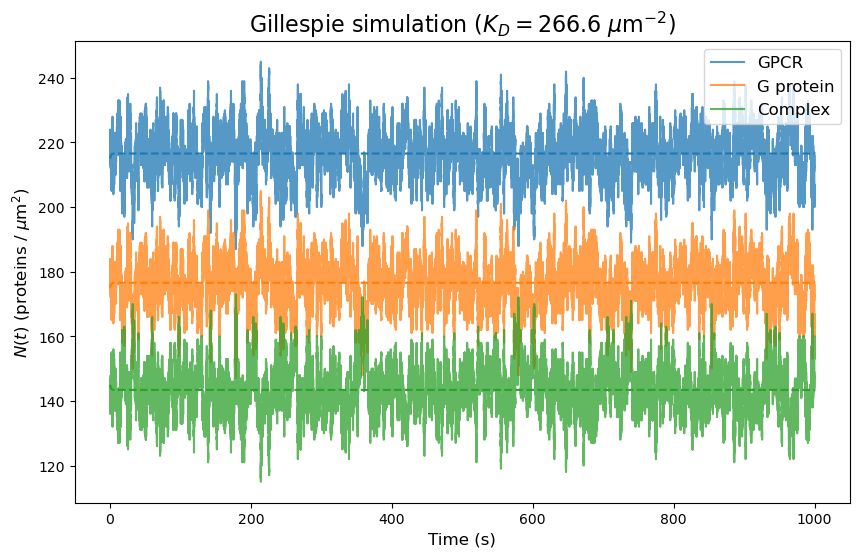

In [ ]:
k_on = 0.0012 #um^2/mol/s or 0.2 or 0.015
k_off = 0.32 # /s 
KD = k_off/k_on
print(KD)

init = 145
Nr_init = 360 - init
Ng_init = 320 - init 
Nrg_init = init

# total numbers here are derived from experimental concentrations in https://www.nature.com/articles/nature24264 
# which give concentrations used for single particle tracking experiments.

Nr, Ng, Nrg, times = run_gillespie(Nr_init, Ng_init, Nrg_init, Tmax=1000, K_on=k_on, K_off=k_off)



#multiple simulation plot
deterNr, deterNg, deterNrg, deterT = solve_deterministic(Nr_init, Ng_init, Nrg_init, 1000, 0.01, k_on, k_off)


plt.figure(figsize=(10, 6))
plt.plot(times, Nr, 'tab:blue', alpha=0.75, label='GPCR')
plt.plot(times, Ng, 'tab:orange', alpha=0.75, label='G protein')
plt.plot(times, Nrg, 'tab:green', alpha=0.75, label='Complex')
plt.plot(deterT, deterNr, 'tab:blue', linestyle='--', label='Deterministic solutions')
plt.plot(deterT, deterNg, 'tab:orange', linestyle='--')
plt.plot(deterT, deterNrg, 'tab:green', linestyle='--')

plt.xlabel('Time (s)', fontsize=12)
plt.ylabel(r'$N(t)$ (proteins / $\mu$m$^2$)', fontsize=12)
# plt.title('Protein complex Gillespie simulation')
plt.legend(fontsize=12, loc='upper right') 
plt.title(f'Gillespie simulation ($K_D=${round(k_off/k_on, 2)} $\mu$m$^{-2}$)', fontsize=16)
plt.show()

99
361.2893371582031
321.7374572753906


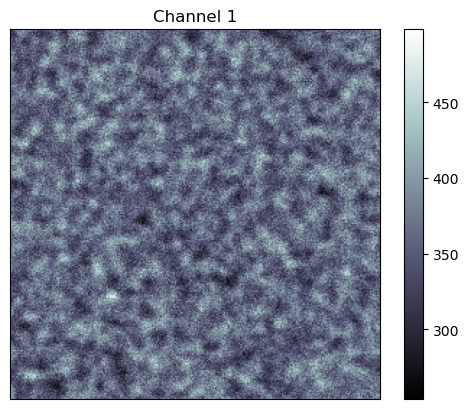

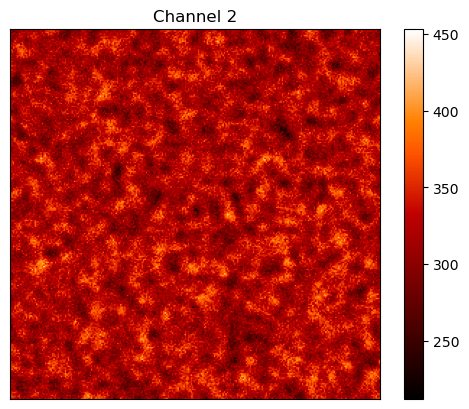

98


In [ ]:
folder = None # directory to save images for simulation.

Nr, Ng, Nrg, times = make_time_series(Nr, Ng, Nrg, times, dt=10)

# Total numbers to um^2 densities (256x256x0.01 um^2/pixel = 655 pixels^2)
nr = Nr#/655
ng = Ng#/655
nrg = Nrg#/655

"""
256 x 256 pixel image with pixel length = 0.1 um^2. Can assume 0.1 um^3 volume
"""
bright = 100
print(len(times))

for i in range(len(times)):
    r = nr[i]
    g = ng[i]
    rg = nrg[i]

    for j in range(2):#5):
        R = sc.Particles(r, D=0, spectrum=[bright, 0])
        G = sc.Particles(g, D=0, spectrum=[0, bright])    
        RG = sc.Particles(rg, D=0, spectrum=[bright, bright])
        # # im = Image(particles=[sD, sA], w=512, h=512, gaussian_radius=0.5, poisson=False )
        im = sc.Image(particles=[R, G, RG], w=256, h=256, gaussian_radius=[0.5, 0.5], poisson=True, background=1)
        path = folder + r'\\' + f'time{i}_sample{j}.tiff'
        im.get_img()
        im.save_img(path)
    if i == 0:
        im.show_image()
print(i)


cumulants, variances = cc.two_color(folder, factorial=True, out=True)


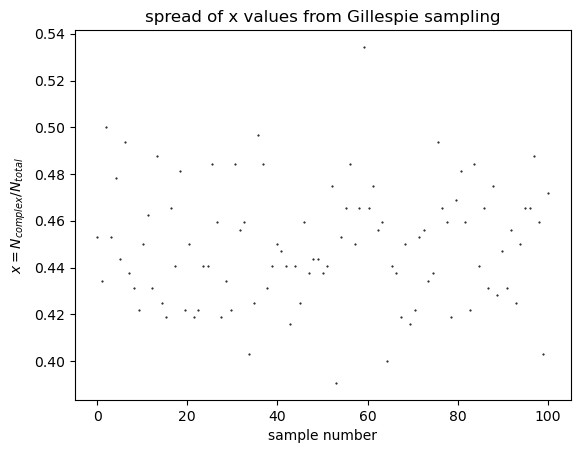

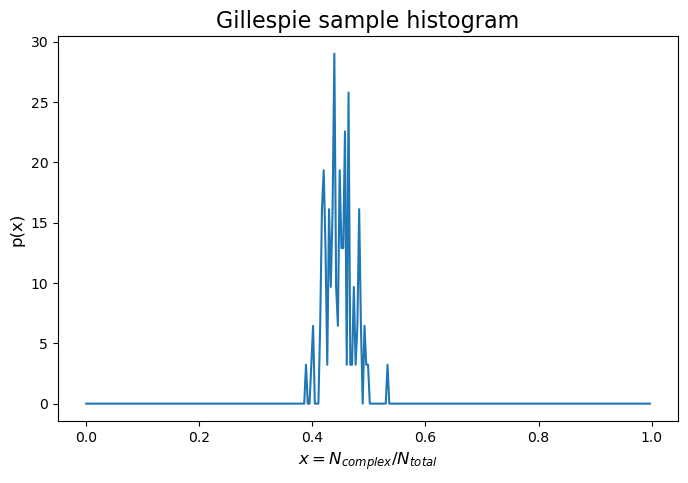

In [21]:
# plot underlying expected result
plt.figure()
plt.title('spread of x values from Gillespie sampling')
plt.scatter(np.linspace(0,100, (len(nrg))), nrg/(nrg+ng), marker='.', color='k', s=1)
plt.xlabel('sample number')
plt.ylabel(r'$x = N_{complex}/N_{total}$')
plt.show()

x_seeds = Nrg/(Nrg+Ng)
vals, bins = np.histogram(x_seeds, np.linspace(0, 1, int(max((Nrg + Ng)))), density=True)
plt.figure(figsize=(8, 5))
plt.title('Gillespie sample histogram', fontsize=16)
plt.ylabel('p(x)', fontsize=12)
plt.xlabel(r'$x = N_{complex}/N_{total}$', fontsize=12)
plt.plot(bins[:-1], vals)
plt.show()


In [22]:
# ims = os.listdir(folder)
# ims = sorted(ims)
n = 2

Rvals = np.zeros(len(times))
Gvals = np.zeros(len(times))
RGvals = np.zeros(len(times))
Rvals_coloc = np.zeros(len(times))
Gvals_coloc = np.zeros(len(times))
RGvals_coloc = np.zeros(len(times))

print(len(times))
print(cumulants.shape)

for i in range(len(times)):
    sub_cumulants = cumulants[i*2:(i+1)*2]
    sub_variances = variances[i*2:(i+1)*2]
    # sub_cumulants = np.atleast_2d(cumulants[i])
    # sub_variances = np.atleast_2d(variances[i])
    N = np.array([1, 1, 1])
    B = np.array([[bright,0], [0,bright], [bright,bright]])
    background = np.array([1, 1])
    e2rad = [5, 5]

    fit = fc.fit_cumulants(N, B, background, e2rad, sub_cumulants, sub_variances, two_color=True, varyN=True, varyB=False, varygamma=False, varyback=True)
    # fit = fc.fit_cumulants_no3(N, B, gamma, background, sub_cumulants, sub_variances, two_color=True, varyN=True, varyB=False, varygamma=False, varyback=True)
    a = fit.params['N1'].value
    b = fit.params['N2'].value
    c = fit.params['N3'].value
    Rvals[i] = a
    Gvals[i] = b
    RGvals[i] = c
    mean_coloc = a*b*np.exp(-(a + b))
    Rvals_coloc[i] = a + mean_coloc
    Gvals_coloc[i] = b + mean_coloc
    RGvals_coloc[i] = c - mean_coloc

    if i == len(times)-1:
        print('nr', nr[0]/100)
        print('ng', ng[0]/100)
        print('nrg', nrg[0]/100)
        print('mean_coloc', mean_coloc)
        print(fit.params)



99
(198, 9)
nr 2.15
ng 1.75
nrg 1.45
mean_coloc 0.0629269804742038
Parameters([('N1', <Parameter 'N1', value=2.361628885374112 +/- 0.0681, bounds=[0:1000]>), ('B1a', <Parameter 'B1a', value=100 (fixed), bounds=[0:5000]>), ('B1b', <Parameter 'B1b', value=0 (fixed), bounds=[0:5000]>), ('N2', <Parameter 'N2', value=1.9112719058770877 +/- 0.065, bounds=[0:1000]>), ('B2a', <Parameter 'B2a', value=0 (fixed), bounds=[0:5000]>), ('B2b', <Parameter 'B2b', value=100 (fixed), bounds=[0:5000]>), ('N3', <Parameter 'N3', value=1.2518430946905634 +/- 0.052, bounds=[0:1000]>), ('B3a', <Parameter 'B3a', value=100 (fixed), bounds=[0:5000]>), ('B3b', <Parameter 'B3b', value=100 (fixed), bounds=[0:5000]>), ('gamma1', <Parameter 'gamma1', value=1 (fixed), bounds=[-inf:inf]>), ('gamma2', <Parameter 'gamma2', value=1.0 (fixed), bounds=[-inf:inf]>), ('gamma3', <Parameter 'gamma3', value=0.012732395447351628 (fixed), bounds=[-inf:inf]>), ('gamma4', <Parameter 'gamma4', value=0.012732395447351628 (fixed), bound

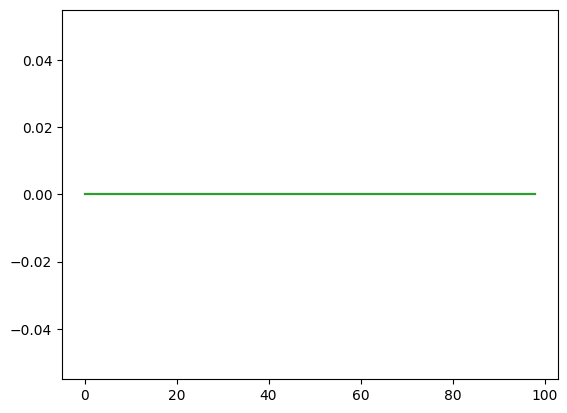

In [23]:
plt.figure()
plt.plot(Rvals)
plt.plot(Gvals)
plt.plot(RGvals)
plt.show()

In [ ]:
# x_seeds = Nrg/(Nrg+Ng)
# vals, bins = np.histogram(x_seeds, np.linspace(0, 1, int(max((Nrg + Ng)))), density=True)

# N_R = np.max(Nrg + Nr)
# N_G = np.max(Nrg + Ng)
# x_fits = Nrg/(Nrg + Ng)

# use this for simulated images, above is just taking gillespie values.
N_R = np.mean(Rvals+RGvals)*100#*256**2
N_G = np.mean(Gvals+RGvals)*100#*256**2
print(N_G)
x_fits = RGvals/(RGvals + Gvals)

print(np.max(Nr + Nrg))
print(np.mean(Rvals + RGvals)*256*256)

<>:74: SyntaxWarning: invalid escape sequence '\p'
<>:74: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Teo\AppData\Local\Temp\ipykernel_24784\852699517.py:74: SyntaxWarning: invalid escape sequence '\p'
  plt.text(0.5, 14, f'Max a posteriori $K_D$: {round(k, 2)} $\pm$ {round(e,2)}\nSeeded $K_D$: {round(k_off/k_on, 2)}', fontsize=12)


316.15531613090866
360.0
232934.88344687453


1.149410447791638 1342.0220721768019


<>:87: SyntaxWarning: invalid escape sequence '\p'
<>:87: SyntaxWarning: invalid escape sequence '\p'
C:\Users\teole\AppData\Local\Temp\ipykernel_20848\4203109498.py:87: SyntaxWarning: invalid escape sequence '\p'
  plt.text(0.5, 14, f'Max a posteriori $K_D$: {round(k, 2)} $\pm$ {round(e,2)}\nSeeded $K_D$: {round(k_off/k_on, 2)}', fontsize=12)


maximum likelihood:  262.41687197169733
integral 0.9999999999999999


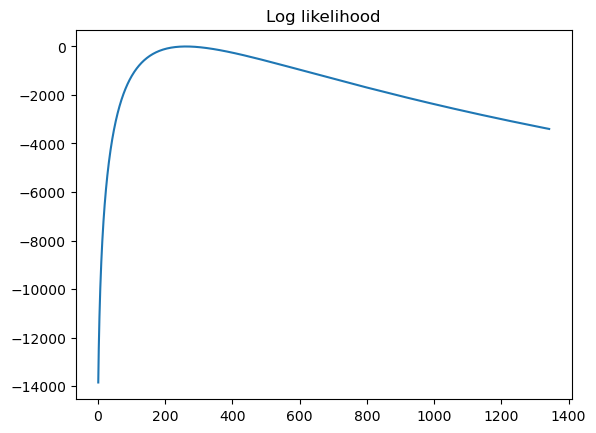

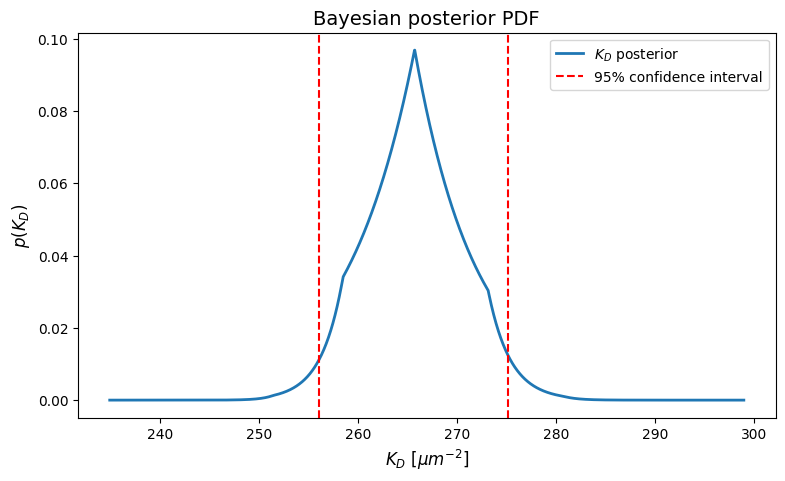

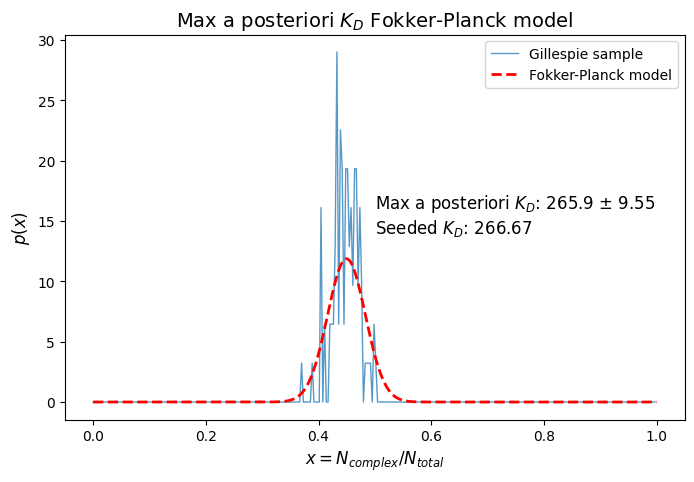

In [ ]:
minseed, maxseed = bf.get_seed(N_G, N_R, offset=0, maxval=True)
print(minseed, maxseed)
KD_grid = np.linspace(minseed, maxseed, int(maxseed-minseed)*2)

log_likelihood, KD_grid = bf.log_likelihood_KD(x_fits, KD_grid, N_G, N_R, maxval=0)
log_likelihood[np.logical_not(np.isfinite(log_likelihood))] = -np.inf
log_likelihood = log_likelihood - (np.max(log_likelihood))

posterior = np.exp(log_likelihood) / (np.sum(np.exp(log_likelihood))*np.diff(KD_grid)[0])
plt.figure()
plt.title('Log likelihood')
plt.plot(KD_grid, log_likelihood)

print('maximum likelihood: ', KD_grid[np.argmax(log_likelihood)])


# just for plotting the best fit
k = KD_grid[np.argmax(log_likelihood)]
xgrid = np.linspace(0,1, 500)
logpdf = bf.log_steady_contKD(xgrid, k, N_G, N_R)
logpdf = logpdf - np.min(logpdf)
pdf = np.exp(logpdf)
pdf = pdf / (np.sum(pdf)*np.diff(xgrid)[0])
print('integral', np.sum(pdf)*np.diff(xgrid)[0])


plt.figure(figsize=(9,5))
plt.plot(KD_grid, posterior, linewidth=2, label='$K_D$ posterior')
plt.title('Coarse Bayesian posterior', fontsize=14)
plt.xlabel(r'$K_D$ [$\mu m^{-2}$]', fontsize=12)
plt.ylabel(r'$p(K_D)$', fontsize=12)
plt.legend()
plt.show()


bounds = bf.get_confidence_interval(posterior, KD_grid, 1-1e-10)

new_grid = np.linspace(bounds[0], bounds[1], max(len(KD_grid), 2000))
log_likelihood, new_grid = bf.log_likelihood_KD(x_fits, new_grid, N_G, N_R, maxval=0)
log_likelihood[np.logical_not(np.isfinite(log_likelihood))] = -np.inf
log_likelihood = log_likelihood - np.max(log_likelihood)
posterior = np.exp(log_likelihood) / (np.sum(np.exp(log_likelihood))*np.diff(new_grid)[0])
MAPKD = new_grid[np.argmax(log_likelihood)]

interval = 0.95
diffvals = bf.get_confidence_interval(posterior, new_grid, interval)
print(diffvals)

print('maximum a posteriori: ', new_grid[np.argmax(posterior)], '(+/-)', (diffvals[1] - diffvals[0])/2)
e = (diffvals[1] - diffvals[0])/2


plt.figure(figsize=(9,5))
plt.plot(new_grid, posterior, linewidth=2, label='$K_D$ posterior')
plt.title('Bayesian posterior PDF', fontsize=14)
plt.xlabel(r'$K_D$ [$\mu m^{-2}$]', fontsize=12)
plt.ylabel(r'$p(K_D)$', fontsize=12)
plt.axvline(diffvals[0], ymin=0, ymax=1, color='r', linestyle='--', linewidth=1.5, label=f'{int(interval*100)}% confidence interval')
plt.axvline(diffvals[1], ymin=0, ymax=1, color='r', linestyle='--', linewidth=1.5)
plt.legend()
plt.show()


plt.figure(figsize=(8,5))
plt.title('Max a posteriori $K_D$ Fokker-Planck model', fontsize=14)
vals, bins = np.histogram(x_seeds, np.linspace(0, 1, int(max((Nrg + Ng)))), density=True)
plt.plot(bins[:-1], vals, linewidth=1, alpha=0.75, label='Gillespie sample')
plt.plot(xgrid, pdf, 'r--', linewidth=2, label='Fokker-Planck model')
plt.xlabel(r'$x = N_{complex}/N_{total}$', fontsize=12)
plt.ylabel('$p(x)$', fontsize=12)
plt.text(0.5, 14, f'Max a posteriori $K_D$: {round(k, 2)} $\pm$ {round(e,2)}\nSeeded $K_D$: {round(k_off/k_on, 2)}', fontsize=12)
plt.legend()
plt.show()
